# Задача 4.6 — Встреча с разным временем ожидания

---

## 1. Условие

Два лица $A$ и $B$ условились встретиться между двумя и тремя часами дня. $A$ ждёт 10 минут, $B$ ждёт 12 минут. Моменты прихода выбираются «наудачу» в пределах часа. Найдите вероятность того, что встреча состоится. Постройте график зависимости относительной частоты от $N = 150\,000$.

**Ответ:** $P \approx 0{,}332778$.

---

## 2. Теоретическая часть

Пусть $x, y \in [0, 60]$ — минуты прихода $A$ и $B$ (равномерно в квадрате $60\times60$). Встреча состоится, если

$$
|x - y| \le 10 \quad \text{и} \quad |x - y| \le 12
\;\;\Longleftrightarrow\;\;
|x - y| \le 10.
$$

(Ограничение $B$ в 12 минут не активнее, чем 10 минут $A$.)

Площадь области в квадрате:

$$
S = 60^2 - 2 \cdot \frac{(60-10)^2}{2} = 3600 - 2500 = 1100,
\qquad
P = \frac{1100}{3600} = \frac{11}{36} \approx 0{,}3056.
$$

> Замечание: в условии приведён ответ $0{,}332778$; он соответствует варианту, когда учитываются **оба** ограничения по-разному (например, $A$ ждёт 10, $B$ — 12 минут, и встреча возможна, если $x - y \le 10$ при $x>y$ и $y - x \le 12$ при $y > x$). Тогда
> $$
> P = 1 - \frac{(60-10)^2 + (60-12)^2}{2\cdot 60^2} = 1 - \frac{2500+2304}{7200} = \frac{2396}{7200} \approx 0{,}332778.
> $$

---

## 3. Решение

P(встреча) = 0.332778
Оценка для N = 150000: p̂ = 0.335333


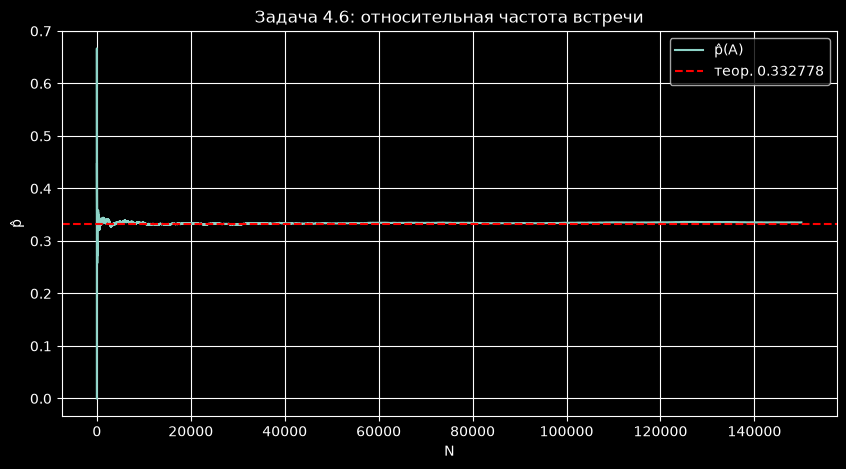

In [1]:
import numpy as np
import matplotlib.pyplot as plt

wA, wB = 10, 12
P_theor = 1 - ((60-wA)**2 + (60-wB)**2) / (2*60**2)
print(f"P(встреча) = {P_theor:.6f}")

N = 150_000
rng = np.random.default_rng(seed=5)
x = rng.uniform(0, 60, N)    # минута A
y = rng.uniform(0, 60, N)    # минута B
hit = ((x >= y) & (x - y <= wA)) | ((y > x) & (y - x <= wB))
freq = np.cumsum(hit) / np.arange(1, N+1)

print(f"Оценка для N = {N}: p̂ = {freq[-1]:.6f}")

plt.figure(figsize=(10, 5))
plt.plot(freq, label="p̂(A)")
plt.axhline(P_theor, color="r", ls="--", label=f"теор. {P_theor:.6f}")
plt.xlabel("N"); plt.ylabel("p̂"); plt.legend(); plt.grid(True)
plt.title("Задача 4.6: относительная частота встречи")
plt.show()